# F3 · Núcleo algorítmico, eficiencia y programación orientada a objetos

**MCDI500 Programación para la Ciencia de Datos** · Magíster en Ciencia de Datos e Inteligencia Artificial · Universidad Andrés Bello
**Proyecto:** Análisis reproducible del Inventario Público de Glaciares de Chile 2022 · **Avance Fase 3 — Semana 2**
**Integrantes:** Francisco Correa Soto · Gustavo Aloy Angella · Roberto Gaubert Urbina · **Docente:** Dr. Omar Salinas Silva

En la Fase 2 construimos un pipeline que funciona: obtiene el inventario de la DGA, lo limpia, imputa, transforma, valida y persiste. Este notebook no cambia los datos ni el pipeline. Cambia la **arquitectura del código**: las mismas operaciones, ahora organizadas en clases que se pueden probar, reemplazar y reutilizar (`src/`). Dentro de ese diseño calcula el resultado principal del proyecto: **cuán concentrada está la superficie glaciar** y por qué la concentración del volumen es una consecuencia de ella.

| Sección | Contenido | Criterio de la pauta |
|---|---|---|
| 0–2 | Entorno, contexto y carga del inventario | II.a |
| 3 | El pipeline de F2 encapsulado en clases | II.b · II.e · III.a |
| 4 | Verificación: ¿las clases reproducen F2? | II.c |
| 5–6 | Concentración de la superficie y volumen como magnitud derivada | II.a · II.e · III.a |
| 7 | Eficiencia: comparación formal de implementaciones | II.d |
| 8 | Recursividad | II.e |
| 9 | Patrones de diseño: Strategy y Observer | III.b |
| 10–11 | Resultados para la Fase 4 y conclusiones | V |

## 0. Entorno, módulos y trazabilidad

Todo el código reutilizable vive en `src/` y se **importa**: este notebook no define clases ni funciones de procesamiento, solo las ejecuta, muestra sus resultados y los interpreta. La raíz del repositorio se localiza desde la carpeta en que Jupyter abra el notebook, así que funciona desde `F3/` o desde la raíz.

In [1]:
import contextlib
import inspect
import io
import sys
import importlib.metadata as metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = next(c for c in (Path.cwd(), *Path.cwd().parents) if (c / "src" / "utilidades.py").is_file())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

import utilidades as utl           # F1–F2: rutas, huella, carga, pruebas y Bitacora
import limpieza as lim             # funciones de F2 (programación estructurada)
import imputacion as imp           # estrategias de imputación (Strategy)
import transformadores as tr       # Transformador y sus clases hijas
import procesamiento as proc       # arma los pipelines de F2 y verifica las salidas
import concentracion as con        # medidas de concentración
import medicion as me              # medición y comparación de implementaciones
import metadatos as md             # aplanado recursivo e iterativo
from pipeline import Pipeline, RegistroEjecucion, ReporteConsola, ObservadorBitacora

np.random.seed(utl.SEMILLA)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

declaradas = utl.leer_requirements(RAIZ / "requirements.txt")
print("Python:", sys.version.split()[0], "| entorno virtual:", "sí" if sys.prefix != sys.base_prefix else "NO")
for paquete in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    instalada = metadata.version(paquete)
    aviso = "" if instalada == declaradas.get(paquete) else f"  ← requirements.txt declara {declaradas.get(paquete)}"
    print(f"{paquete}: {instalada}{aviso}")
print("Módulos de src/:", sorted(p.name for p in (RAIZ / "src").glob("*.py")))

Python: 3.14.10 | entorno virtual: sí
numpy: 2.5.4
pandas: 3.1.1
scikit-learn: 1.9.1
matplotlib: 3.11.2
Módulos de src/: ['comunicacion.py', 'concentracion.py', 'figuras.py', 'imputacion.py', 'limpieza.py', 'medicion.py', 'metadatos.py', 'pipeline.py', 'procesamiento.py', 'pruebas_comunicacion.py', 'pruebas_concentracion.py', 'pruebas_figuras.py', 'pruebas_medicion.py', 'pruebas_nucleo.py', 'transformadores.py', 'utilidades.py']


In [2]:
SALIDAS_F3 = ["F3", "data/processed", "docs/bitacora_f3.md", "docs/metadatos_f3.csv"]   # el propio notebook y sus salidas
print("Repositorio:", utl.version_repositorio(RAIZ, excluir=SALIDAS_F3))
print("Identidad de Git:", utl.identidad_git(RAIZ))

Repositorio: {'rama': 'f4-theil', 'commit': '5373480', 'cambios_sin_commit': True}
Identidad de Git: {'user.name': 'Francisco Correa', 'user.email': 'f.correasoto@uandresbello.edu', 'email_valido': True}


## 1. Contexto y objetivo de la Fase 3

**Problemática.** Los glaciares son reservas hídricas estratégicas para Chile. La DGA publica el inventario oficial (26.180 glaciares, 45 variables), pero no un cálculo reproducible de cuán concentrada está la superficie glaciar.

**Pregunta de investigación.** ¿Qué tan concentrada está la superficie glaciar en pocos glaciares y regiones, y cambia esa concentración según la clasificación del glaciar?

**Por qué la superficie y no el volumen.** En F2 (sección 2.3) verificamos que el espesor y el volumen **no son mediciones**: la DGA los estimó desde el área con la relación de Chen y Ohmura (1990), `ESP_MED = 28,5 · AREA^0,357`, de modo que `VOL ≈ 0,0285 · AREA^1,357`. La superficie es la magnitud observada; el volumen es una magnitud derivada, y su concentración no puede ser un hallazgo independiente. La sección 6 lo demuestra con datos.

**Integración con lo anterior.**
- *Fase 2:* el pipeline (secciones 3–6 de F2), la regla para elegir la imputación, la bitácora y la función recursiva `aplanar` (F2 sección 7) se trasladan a `src/` sin cambios de lógica.

## 2. Carga del inventario original

`proc.cargar_original` verifica la huella SHA-256 del CSV de `data/raw/` **antes** de leerlo y se detiene con `ProyectoError` si el archivo no es la versión registrada. El archivo original nunca se modifica: cada paso del pipeline trabaja sobre una copia.

In [3]:
RUTA_ORIGINAL = RAIZ / "data" / "raw" / utl.ARCHIVO_INVENTARIO
original = proc.cargar_original(RAIZ)
huella_inicial = utl.huella_sha256(RUTA_ORIGINAL)
print(f"Inventario: {original.shape[0]:,} filas × {original.shape[1]} columnas | SHA-256 {huella_inicial[:16]}…")

Inventario: 26,180 filas × 45 columnas | SHA-256 5691de5d7d7ffe2c…


## 3. El pipeline de F2 encapsulado en clases

### 3.1 Ejecutar y observar

`proc.verificar_reproduccion` ejecuta los tres pipelines de F2 (limpieza, formato y modelo) con las clases de `src/` y compara sus salidas con las versionadas por F2. Le suscribimos dos observadores: `ReporteConsola` imprime cada paso mientras ocurre y `RegistroEjecucion` lo acumula como tabla. El pipeline no sabe quién lo observa (sección 9).

In [4]:
registro = RegistroEjecucion()
verificacion, limpio, modelo, pipelines = proc.verificar_reproduccion(RAIZ, observadores=[ReporteConsola(), registro])
print(f"\nglaciares_limpio: {limpio.shape} | glaciares_modelo: {modelo.shape}")

  limpieza   DescartadorColumnas                   26180 filas ×  37 col  [0.049 s]


  limpieza   NormalizadorTexto                     26180 filas ×  37 col  [0.096 s]
  limpieza   ConversorTipos                        26180 filas ×  38 col  [0.065 s]
  limpieza   ReconstructorVolumen                  26180 filas ×  40 col  [0.021 s]
  limpieza   MarcadorFaltantes                     26180 filas ×  40 col  [0.007 s]


  limpieza   ImputadorEstrategia(HMIN)             26180 filas ×  41 col  [0.075 s]
  limpieza   ImputadorPuntoMedio(HMEDIA)           26180 filas ×  42 col  [0.006 s]
  limpieza   DerivadorVariables                    26180 filas ×  48 col  [0.013 s]
  formato    Redondeador                           26180 filas ×  48 col  [0.007 s]


  formato    Categorizador                         26180 filas ×  48 col  [0.016 s]
  modelo     CodificadorOrdinal(MZON_GLAC)         26180 filas ×  49 col  [0.019 s]
  modelo     CodificadorOrdinal(CLASE_TAMANO)      26180 filas ×  50 col  [0.020 s]
  modelo     CodificadorCiclico                    26180 filas ×  52 col  [0.014 s]
  modelo     EscaladorRobusto                      26180 filas ×  56 col  [0.020 s]
  modelo     CodificadorOneHot                     26180 filas ×  88 col  [0.039 s]



glaciares_limpio: (26180, 48) | glaciares_modelo: (26180, 47)


Los 15 pasos conservan las 26.180 filas (la clase base lo comprueba en cada paso). La limpieza pasa de 45 a 48 columnas: descarta 9 sin información y agrega banderas y derivadas; el pipeline del modelo agrega ordinales, cíclicas, escaladas y 32 columnas one-hot.

### 3.2 Arquitectura

Cada archivo de `src/` tiene una sola responsabilidad (alta cohesión) y depende solo de los que están por debajo (bajo acoplamiento):

| Archivo | Responsabilidad | Depende de |
|---|---|---|
| `utilidades.py` | Rutas, huella, carga, pruebas y bitácora (F1–F2) | — |
| `limpieza.py` | Funciones de limpieza y codificación (estructuradas, sin estado) | — |
| `imputacion.py` | Estrategias de imputación intercambiables (Strategy) | utilidades |
| `transformadores.py` | Clase base `Transformador` y una clase hija por paso | limpieza, imputacion |
| `pipeline.py` | `Pipeline` (composición) y observadores (Observer) | transformadores |
| `procesamiento.py` | **Única** que conoce la configuración del proyecto: qué pasos, en qué orden | todas las anteriores |
| `concentracion.py` | Medidas de concentración y relación área → volumen | — |
| `medicion.py`, `metadatos.py` | Medición de eficiencia y recursividad | — |

**Prueba operacional del acoplamiento:** para cambiar la estrategia de imputación hay que modificar **un solo archivo** (`procesamiento.py`, o ninguno si se pasa como parámetro, sección 9).

In [5]:
for nombre, pipeline in pipelines.items():
    print(f"Pipeline «{nombre}»: {len(pipeline)} pasos")
    display(pipeline.resumen())

Pipeline «limpieza»: 8 pasos


,orden,paso,clase,clase_base
0,1,DescartadorColumnas,DescartadorColumnas,Transformador
1,2,NormalizadorTexto,NormalizadorTexto,Transformador
2,3,ConversorTipos,ConversorTipos,Transformador
3,4,ReconstructorVolumen,ReconstructorVolumen,Transformador
4,5,MarcadorFaltantes,MarcadorFaltantes,Transformador
5,6,ImputadorEstrategia(HMIN),ImputadorEstrategia,Transformador
6,7,ImputadorPuntoMedio(HMEDIA),ImputadorPuntoMedio,Transformador
7,8,DerivadorVariables,DerivadorVariables,Transformador


Pipeline «formato»: 2 pasos


,orden,paso,clase,clase_base
0,1,Redondeador,Redondeador,Transformador
1,2,Categorizador,Categorizador,Transformador


Pipeline «modelo»: 5 pasos


,orden,paso,clase,clase_base
0,1,CodificadorOrdinal(MZON_GLAC),CodificadorOrdinal,Transformador
1,2,CodificadorOrdinal(CLASE_TAMANO),CodificadorOrdinal,Transformador
2,3,CodificadorCiclico,CodificadorCiclico,Transformador
3,4,EscaladorRobusto,EscaladorRobusto,Transformador
4,5,CodificadorOneHot,CodificadorOneHot,Transformador


### 3.3 Herencia

Todas las clases de paso heredan de `Transformador`, que escribe **una sola vez** lo que comparten: validar la entrada, controlar que se ajuste antes de transformar, copiar el DataFrame antes de modificarlo y comprobar que no se pierdan filas (método plantilla). Cada clase hija implementa solo `aprender` (qué estima de los datos) y `aplicar` (cómo lo usa). La cadena de resolución de métodos (MRO) muestra de dónde hereda cada una:

In [6]:
for paso in (pipelines["limpieza"]["ImputadorEstrategia(HMIN)"], pipelines["modelo"]["EscaladorRobusto"]):
    print(f"{paso.nombre:<28} es Transformador: {isinstance(paso, tr.Transformador)} | MRO: {[c.__name__ for c in type(paso).__mro__]}")
propios = {c.__name__: sorted(m for m in vars(c) if m in ("aprender", "aplicar", "ajustar", "transformar"))
           for c in (tr.ReconstructorVolumen, tr.ImputadorEstrategia, tr.EscaladorRobusto)}
print("Métodos que define cada clase hija:", propios)
print("Métodos que define la clase base:  ", sorted(m for m in ("aprender", "aplicar", "ajustar", "transformar") if m in vars(tr.Transformador)))

ImputadorEstrategia(HMIN)    es Transformador: True | MRO: ['ImputadorEstrategia', 'Transformador', 'ABC', 'object']
EscaladorRobusto             es Transformador: True | MRO: ['EscaladorRobusto', 'Transformador', 'ABC', 'object']
Métodos que define cada clase hija: {'ReconstructorVolumen': ['aplicar', 'aprender'], 'ImputadorEstrategia': ['aplicar', 'aprender'], 'EscaladorRobusto': ['aplicar', 'aprender']}
Métodos que define la clase base:   ['ajustar', 'aplicar', 'aprender', 'transformar']


Las clases hijas no redefinen `ajustar` ni `transformar`: los heredan. Si mañana cambia el control de estado, se modifica en un solo lugar.

### 3.4 Polimorfismo

El bucle de `Pipeline.ajustar_transformar` llama `ajustar` y `transformar` sobre cada paso **sin preguntar de qué clase es**. No hay ningún `if` sobre el tipo: esa ausencia es la evidencia del polimorfismo, y es lo que permite agregar un paso nuevo sin modificar el pipeline (principio de abierto y cerrado).

In [7]:
print(inspect.getsource(Pipeline.ajustar_transformar))

    def ajustar_transformar(self, df):
        """Ajusta cada paso con la salida del anterior y devuelve el resultado final (una pasada)."""
        if not self._pasos:
            raise RuntimeError(f"{self.nombre}: no tiene pasos")
        resultado = df
        for paso in self._pasos:                                   # polimorfismo
            inicio = time.perf_counter()
            resultado = paso.ajustar(resultado).transformar(resultado)
            self._notificar(paso, resultado, time.perf_counter() - inicio, "ajustar_transformar")
        self._ajustado = True
        return resultado



### 3.5 Encapsulamiento

El estado de cada paso es interno (`_parametros`, `_ajustado`, `_evidencia`) y solo se lee mediante propiedades que devuelven **copias**. Dos consecuencias verificables: un uso incorrecto falla con un mensaje claro en vez de producir un resultado sin sentido, y modificar lo que se lee no altera el objeto.

In [8]:
try:
    tr.MarcadorFaltantes().transformar(original)
except RuntimeError as error:
    print("Error esperado al transformar sin ajustar →", error)

paso = pipelines["limpieza"]["ReconstructorVolumen"]
copia = paso.parametros
copia["factor_hielo"] = {"GLACIAR ROCOSO": 999}
print("Factor de hielo tras modificar la copia:", paso.parametros["factor_hielo"])

Error esperado al transformar sin ajustar → MarcadorFaltantes: hay que ajustar antes de transformar
Factor de hielo tras modificar la copia: {'GLACIAR ROCOSO': 0.6}


### 3.6 Qué aprendió cada paso y por qué

Cada transformación conserva la justificación de F2; ahora la evidencia la produce el propio objeto al ejecutarse, no una anotación posterior:

| Paso | Justificación (F2) |
|---|---|
| `DescartadorColumnas` | 100 % vacías, valor único o redundantes; `CH_CASQ` (97,24 % faltante) pasa a bandera |
| `NormalizadorTexto` | Codificación rota (`FOTOGRAMETR├ìA`), mayúsculas y espacios inconsistentes |
| `ConversorTipos` | Coordenadas como texto con coma decimal, fechas en tres formatos, códigos leídos como enteros |
| `ReconstructorVolumen` | 362 volúmenes en 0 por redondeo; se recalculan con la fórmula del inventario, que el paso verifica en los datos |
| `MarcadorFaltantes` + `ImputadorEstrategia` | 33 `HMIN = 0` en tierra o lago son faltantes encubiertos; la estrategia se elige con una regla declarada (sección 9) |
| `ImputadorPuntoMedio` | Un glaciar con `HMEDIA < HMIN`; el punto medio respeta la restricción física |
| `DerivadorVariables` | Asimetría 43 del área → log10; clases de tamaño en la escala del dominio |
| `EscaladorRobusto` | `RANGO_ALT` y `HMEDIA` conservan colas largas: RobustScaler frente a StandardScaler y MinMax |

In [9]:
filas = []
for nombre_pipeline, pipeline in pipelines.items():
    for paso in pipeline.pasos:
        filas.append({"pipeline": nombre_pipeline, "paso": paso.nombre,
                      "evidencia": "; ".join(f"{k} = {v}" for k, v in paso.evidencia.items()) or "—"})
display(pd.DataFrame(filas))

,pipeline,paso,evidencia
0,limpieza,DescartadorColumnas,descartadas = 9; EN_CAMPO_HIELO = 723
1,limpieza,NormalizadorTexto,"valores_corregidos = 139; por_columna = {'NOMBRE': 5, 'FUENTE_DIG': 6, 'NOM_..."
2,limpieza,ConversorTipos,coordenadas_nulas = 0; fechas_completas = 26168; anios = 26180
3,limpieza,ReconstructorVolumen,volumenes = 362; equivalentes = 668
4,limpieza,MarcadorFaltantes,HMIN = 33; HMEDIA = 1
5,limpieza,ImputadorEstrategia(HMIN),metodo = HMEDIA − desnivel mediano por comuna; imputados = 33
6,limpieza,ImputadorPuntoMedio(HMEDIA),imputados = 1
7,limpieza,DerivadorVariables,asimetria_log_area = 0.61; asimetria_log_vol = 0.69
8,formato,Redondeador,—
9,formato,Categorizador,—


## 4. Verificación: ¿las clases reproducen F2?

Si el pipeline con clases produce **exactamente** los mismos archivos que el código de F2, la reorganización no rompió nada. Es la prueba más estricta posible: se comparan las huellas SHA-256 de los CSV, de modo que una diferencia en un solo decimal o en el orden de una columna la haría fallar.

In [10]:
display(verificacion)
assert verificacion["identico"].all(), "Las clases no reproducen F2"
print("Los tres archivos de data/processed son idénticos byte a byte a los de F2.")

,archivo,sha256_F2,sha256_F3,identico
0,glaciares_limpio.csv,ee220b05825da962,ee220b05825da962,True
1,glaciares_modelo.csv,9636c02fccd59e38,9636c02fccd59e38,True
2,perfil_glaciares_limpio.csv,d12e9e68b5f8a70a,d12e9e68b5f8a70a,True


Los tres archivos de data/processed son idénticos byte a byte a los de F2.


Como segunda comprobación, comparamos los DataFrames con `pd.testing.assert_frame_equal`. Hay que indicar `check_dtype=False`: pandas distingue la variante de texto `str` (la del DataFrame en memoria) de `string` (la que aparece al releer el CSV con `cargar_limpio`), aunque los valores sean idénticos. Por eso la comparación byte a byte del archivo es la evidencia principal.

In [11]:
referencia_f2 = utl.cargar_limpio(RAIZ / "data" / "processed" / "glaciares_limpio.csv")
pd.testing.assert_frame_equal(limpio, referencia_f2, check_dtype=False, check_categorical=False)
print("assert_frame_equal: mismos valores, columnas e índice que glaciares_limpio.csv de F2")

assert_frame_equal: mismos valores, columnas e índice que glaciares_limpio.csv de F2


**Pruebas del núcleo.** `src/pruebas_nucleo.py` reúne 29 pruebas de los transformadores, las estrategias y el pipeline en los tres escenarios que pide la pauta: casos normales (el flujo esperado), casos límite (una fila, columna sin nulos, escala constante, grupo no visto) y excepciones (transformar sin ajustar, columna ausente, tipo equivocado, paso que pierde filas).

In [12]:
import pruebas_nucleo
resultado_nucleo = utl.ejecutar_pruebas(pruebas_nucleo.pruebas())
display(resultado_nucleo)
assert resultado_nucleo["resultado"].eq("OK").all(), "Hay pruebas del núcleo fallidas"
print(f"{len(resultado_nucleo)}/{len(resultado_nucleo)} OK:", resultado_nucleo["tipo"].value_counts().to_dict())

,tipo,prueba,resultado
0,normal,"DescartadorColumnas quita vacías, WGI_1 y OBJECTID y crea EN_CAMPO_HIELO",OK
1,normal,NormalizadorTexto repara 'FOTOGRAMETR├ìA' y cuenta los cambios,OK
2,normal,ReconstructorVolumen aplica AREA·ESP/1000 y marca la bandera,OK
3,normal,MarcadorFaltantes respeta el cero en fiordo y marca el de tierra,OK
4,normal,Strategy: el imputador elige la estrategia sin violaciones y respeta HMIN ≤ ...,OK
5,normal,Strategy: cambiar la estrategia no modifica la clase que imputa,OK
6,normal,Lo aprendido en ajustar se aplica a otro conjunto (sin fuga de datos),OK
7,normal,CodificadorOneHot no crea columnas para categorías no vistas al ajustar,OK
8,normal,Observer: el pipeline notifica un evento por paso,OK
9,normal,Ningún paso modifica el DataFrame de entrada,OK


31/31 OK: {'excepción': 15, 'normal': 11, 'límite': 5}


## 5. Resultado principal: concentración de la superficie

Tres medidas responden la pregunta, cada una como clase hija de `MedidaConcentracion`:

- **Participación de los mayores:** % de la superficie que reúne el 1 % (261) y el 10 % (2.618) de los glaciares más grandes.
- **Índice de Gini:** 0 si todos los glaciares tuvieran la misma superficie; cercano a 1 si uno solo la concentrara.
- **Curva de Lorenz:** la versión gráfica del Gini.

`AnalisisConcentracion` aplica cualquier lista de medidas a una magnitud sin preguntar su tipo (polimorfismo, igual que el pipeline).

In [13]:
superficie = con.AnalisisConcentracion(limpio, "AREA_KM2", con.medidas_proyecto())
resumen_superficie = superficie.resumen()
display(pd.DataFrame([resumen_superficie]).round(3))

,magnitud,glaciares,total,pct_1%_mayores,pct_10%_mayores,gini
0,AREA_KM2,26180,21012.341,71.525,91.096,0.937


**Interpretación.** El 1 % de los glaciares (261) reúne el **71,5 %** de los 21.012 km² de superficie glaciar del país, y el 10 % reúne el **91,1 %**. El Gini de **0,937** es extremo: el 90 % restante de los glaciares, más de 23.000, aporta menos de una décima parte de la superficie.

### 5.1 Por región

In [14]:
por_region = superficie.por_grupo("REGION")
display(por_region.round(3))
dos_mayores = por_region["pct"].iloc[:2].sum()
print(f"{' y '.join(por_region.index[:2])}: {dos_mayores:.1f} % de la superficie")

,glaciares,total,pct,pct_acumulado,pct_1%_mayores,pct_10%_mayores,gini
REGION,,,,,,,
MAGALLANES Y ANTARTICA CHILENA,7055,10426.606,49.621,49.621,67.557,92.652,0.944
AYSEN DEL GENERAL CARLOS IBAÑEZ DEL CAMPO,10301,8723.680,41.517,91.138,76.274,92.371,0.949
LOS LAGOS,3025,614.545,2.925,94.063,30.482,75.955,0.843
METROPOLITANA DE SANTIAGO,1254,450.378,2.143,96.206,25.542,69.233,0.773
LIBERTADOR BERNARDO O HIGGINS,776,269.771,1.284,97.490,39.749,76.672,0.842
VALPARAISO,765,161.939,0.771,98.261,27.607,59.400,0.709
ATACAMA,863,91.971,0.438,98.699,17.537,57.446,0.685
COQUIMBO,898,84.100,0.400,99.099,11.971,48.658,0.625
ARAUCANIA,115,56.176,0.267,99.366,18.547,74.526,0.855


MAGALLANES Y ANTARTICA CHILENA y AYSEN DEL GENERAL CARLOS IBAÑEZ DEL CAMPO: 91.1 % de la superficie


Magallanes y Aysén, donde están los Campos de Hielo Norte y Sur, reúnen el **91,1 %** de la superficie. Dentro de esas dos regiones la concentración también es extrema (Gini 0,94–0,95); en las regiones del norte es menor (0,50–0,69), porque predominan glaciares pequeños de tamaño parecido.

### 5.2 Por clasificación: ¿cambia la concentración según el tipo de glaciar?

In [15]:
por_clase = superficie.por_grupo("CLASIFICA")
por_clase.insert(1, "pct_glaciares", 100 * por_clase["glaciares"] / por_clase["glaciares"].sum())
display(por_clase.round(3))

,glaciares,pct_glaciares,total,pct,pct_acumulado,pct_1%_mayores,pct_10%_mayores,gini
CLASIFICA,,,,,,,,
GLACIAR EFLUENTE,217,0.829,13737.600,65.379,65.379,11.179,57.684,0.709
GLACIAR DE MONTAÑA,3844,14.683,4128.051,19.646,85.025,10.415,40.589,0.499
GLACIAR DE VALLE,310,1.184,1870.420,8.902,93.926,9.308,40.482,0.535
GLACIARETE,18211,69.561,792.202,3.770,97.696,5.549,41.485,0.602
GLACIAR ROCOSO,3598,13.743,484.068,2.304,100.000,11.844,46.490,0.594


**Sí cambia, y es la parte más informativa del resultado.**

- Los **glaciares efluentes** (que descienden desde los campos de hielo) son el 0,8 % de los glaciares (217) y reúnen el **65,4 %** de la superficie.
- Los **glaciaretes** son el 69,6 % de los glaciares (18.211) y aportan solo el **3,8 %**.
- **Dentro** de cada clasificación el Gini es moderado (0,50 a 0,71), mientras que en el total es 0,937. Gran parte de la concentración se explica por el **tipo** de glaciar: pocos glaciares de un tipo muy grande frente a muchos de tipos pequeños.

### 5.3 Curva de Lorenz de la superficie

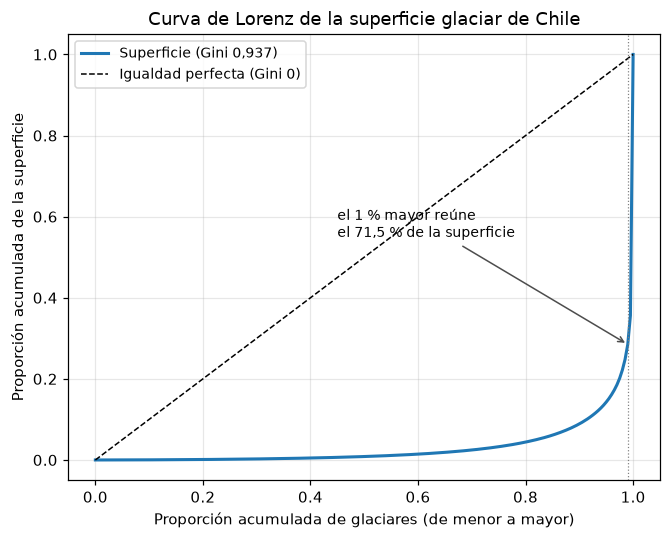

In [16]:
curva_superficie = superficie.curva()
fig, eje = plt.subplots(figsize=(6.2, 5))
eje.plot(curva_superficie["prop_glaciares"], curva_superficie["prop_magnitud"], color="tab:blue", lw=2,
         label=f"Superficie (Gini {resumen_superficie['gini']:.3f})".replace(".", ","))
eje.plot([0, 1], [0, 1], "k--", lw=1, label="Igualdad perfecta (Gini 0)")
eje.axvline(0.99, color="0.5", lw=0.8, ls=":")
eje.annotate("el 1 % mayor reúne\nel 71,5 % de la superficie", xy=(0.99, 1 - 0.715), xytext=(0.45, 0.55),
             arrowprops={"arrowstyle": "->", "color": "0.3"}, fontsize=9)
eje.set(xlabel="Proporción acumulada de glaciares (de menor a mayor)", ylabel="Proporción acumulada de la superficie",
        title="Curva de Lorenz de la superficie glaciar de Chile")
eje.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

La curva se mantiene casi pegada al eje horizontal hasta el 90 % de los glaciares y sube bruscamente al final: la superficie está en la cola de glaciares grandes.

### 5.4 La jerarquía de las medidas

`MedidaConcentracion` es un segundo ejemplo de los tres principios. Su método `calcular` valida una sola vez (sin nulos, sin negativos, conjunto no vacío) y delega en `_calcular`, que cada clase hija implementa:

In [17]:
for medida in [*con.medidas_proyecto(), con.CurvaLorenz()]:
    print(f"{medida!r:<30} etiqueta = {medida.etiqueta:<18} MRO: {[c.__name__ for c in type(medida).__mro__][:-1]}")
try:
    con.IndiceGini().calcular([1.0, -2.0])
except ValueError as error:
    print("Validación heredada de la clase base →", error)

ParticipacionMayores(0.01)     etiqueta = pct_1%_mayores     MRO: ['ParticipacionMayores', 'MedidaConcentracion', 'ABC']
ParticipacionMayores(0.1)      etiqueta = pct_10%_mayores    MRO: ['ParticipacionMayores', 'MedidaConcentracion', 'ABC']
IndiceGini()                   etiqueta = gini               MRO: ['IndiceGini', 'MedidaConcentracion', 'ABC']
CurvaLorenz()                  etiqueta = lorenz             MRO: ['CurvaLorenz', 'MedidaConcentracion', 'ABC']
Validación heredada de la clase base → gini: hay valores negativos


## 6. El volumen como magnitud derivada

El volumen del inventario no se midió: se calculó desde el área. Si su concentración fuera un hallazgo independiente, el volumen calculado **solo con la superficie** debería concentrarse de otra forma. `con.comparar_magnitudes` lo comprueba con tres magnitudes:

1. `AREA_KM2`: la superficie (observada).
2. `VOL_km3`: el volumen publicado por la DGA.
3. `VOL_DESDE_AREA`: un volumen que calculamos con `0,0285 · AREA^1,357` (× 0,6 en glaciares rocosos), sin usar ningún otro dato.

In [18]:
magnitudes = con.comparar_magnitudes(limpio, con.medidas_proyecto())
display(magnitudes.round(3))
fila = magnitudes.set_index("magnitud")
assert np.isclose(fila.loc["VOL_km3", "gini"], fila.loc["VOL_DESDE_AREA", "gini"], atol=5e-4)
print(f"Correlación entre el volumen publicado y el calculado desde el área: "
      f"{np.corrcoef(limpio['VOL_km3'], con.volumen_desde_area(limpio))[0, 1]:.6f}")

,magnitud,glaciares,total,pct_1%_mayores,pct_10%_mayores,gini
0,AREA_KM2,26180,21012.341,71.525,91.096,0.937
1,VOL_km3,26180,3026.198,93.780,99.085,0.991
2,VOL_DESDE_AREA,26180,3026.197,93.780,99.085,0.991


Correlación entre el volumen publicado y el calculado desde el área: 1.000000


**El volumen calculado solo desde la superficie reproduce exactamente la concentración del volumen publicado** (93,8 % en el 1 % mayor, 99,1 % en el 10 % y Gini 0,991). La concentración del volumen no contiene información adicional: es la de la superficie, **amplificada** por el exponente.

**Por qué se amplifica.** Como 1,357 > 1, el volumen crece más rápido que el área: multiplicar la superficie por *k* multiplica el volumen por *k*^1,357.

In [19]:
for k in (2, 10, 100):
    print(f"Un glaciar {k:>3} veces más extenso tiene {k ** con.EXPONENTE_VOLUMEN:,.1f} veces más volumen")

Un glaciar   2 veces más extenso tiene 2.6 veces más volumen
Un glaciar  10 veces más extenso tiene 22.8 veces más volumen
Un glaciar 100 veces más extenso tiene 517.6 veces más volumen


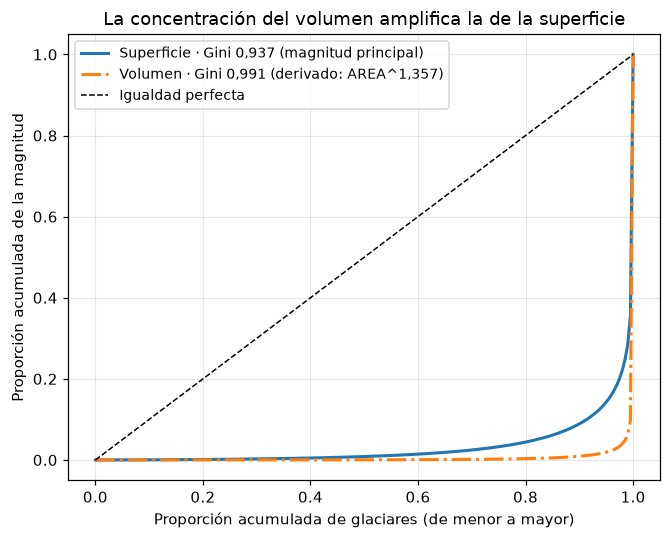

In [20]:
curva_volumen = con.AnalisisConcentracion(limpio, "VOL_km3", con.medidas_proyecto()).curva()
fig, eje = plt.subplots(figsize=(6.2, 5))
eje.plot(curva_superficie["prop_glaciares"], curva_superficie["prop_magnitud"], color="tab:blue", lw=2,
         label=f"Superficie · Gini {fila.loc['AREA_KM2', 'gini']:.3f}".replace(".", ",") + " (magnitud principal)")
eje.plot(curva_volumen["prop_glaciares"], curva_volumen["prop_magnitud"], color="tab:orange", lw=2, ls="-.",
         label=f"Volumen · Gini {fila.loc['VOL_km3', 'gini']:.3f}".replace(".", ",") + " (derivado: AREA^1,357)")
eje.plot([0, 1], [0, 1], "k--", lw=1, label="Igualdad perfecta")
eje.set(xlabel="Proporción acumulada de glaciares (de menor a mayor)", ylabel="Proporción acumulada de la magnitud",
        title="La concentración del volumen amplifica la de la superficie")
eje.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Conclusión.** El resultado del proyecto es la concentración de la **superficie**. La del volumen se reporta como magnitud derivada: es mayor porque el volumen es una función convexa del área, no porque exista un segundo fenómeno. Por la misma razón el proyecto no estudia relaciones entre área y volumen (F1, fuera del alcance).

Las pruebas de `src/pruebas_concentracion.py` fijan estas cifras como **cifras de control**: si un cambio en el código las alterara, la prueba fallaría.

In [21]:
import pruebas_concentracion
resultado_concentracion = utl.ejecutar_pruebas(pruebas_concentracion.pruebas())
display(resultado_concentracion)
assert resultado_concentracion["resultado"].eq("OK").all(), "Hay pruebas de concentración fallidas"
print(f"{len(resultado_concentracion)}/{len(resultado_concentracion)} OK:", resultado_concentracion["tipo"].value_counts().to_dict())

,tipo,prueba,resultado
0,normal,"Participación del 50 % mayor en [1, 2, 3, 4] = 70 %",OK
1,normal,"Gini de [1, 2, 3, 4] = 0,25",OK
2,normal,"Lorenz empieza en (0, 0) y termina en (1, 1)",OK
3,normal,Polimorfismo: el análisis acepta cualquier MedidaConcentracion,OK
4,normal,por_grupo suma 100 % y está ordenado de mayor a menor,OK
5,límite,Gini de valores iguales = 0,OK
6,límite,Gini con un solo glaciar con todo = (n − 1) / n,OK
7,límite,Participación con fracción 1 = 100 %,OK
8,límite,Un solo valor: Gini 0 y Lorenz de dos puntos,OK
9,límite,El análisis no modifica el DataFrame recibido,OK


32/32 OK: {'excepción': 12, 'límite': 8, 'normal': 7, 'control': 5}


## 7. Eficiencia y optimización

### 7.1 Método de medición

`src/medicion.py` aplica las tres reglas del apunte de la Fase 3:

1. **Repetir y conservar el mínimo** (`timeit.repeat`): los tiempos altos reflejan interferencia del sistema operativo, no el costo del código (Python Software Foundation, s. f.-a).
2. **Medir sobre tamaños crecientes**, incluido el tamaño real del inventario.
3. **Verificar equivalencia antes de comparar:** `me.comparar` se detiene con `ProyectoError` si dos implementaciones no dan el mismo resultado.

La memoria pico se mide con `tracemalloc` en una ejecución aparte, para no contaminar el tiempo (Python Software Foundation, s. f.-b).

**Método formal.** `me.exponente_empirico` ajusta por mínimos cuadrados log(t) = a + b·log(n). La pendiente *b* estima el orden de crecimiento observado (b ≈ 1 lineal, b ≈ 2 cuadrático), que se contrasta con la complejidad teórica de cada implementación.

### 7.2 Índice de Gini: tres implementaciones

| Implementación | Idea | Tiempo | Memoria |
|---|---|---|---|
| `gini_pares_matriz` | Definición Σᵢ Σⱼ \|xᵢ − xⱼ\| con una matriz n × n | O(n²) | O(n²) |
| `gini_pares_bucle` | La misma definición, una fila a la vez | O(n²) | O(n) |
| `gini_ordenado` | Fórmula sobre los valores ordenados (la de `IndiceGini`) | O(n log n) | O(n) |

La versión matriz no se mide con más de 8.000 glaciares: con 26.180 necesitaría una matriz de 685 millones de celdas (≈ 5,5 GB solo para ella).

In [22]:
muestras_gini = me.muestras(limpio["AREA_KM2"], [1000, 2000, 4000, 8000])
t_gini = me.comparar({"pares_matriz": me.gini_pares_matriz, "pares_bucle": me.gini_pares_bucle,
                      "ordenado": me.gini_ordenado}, muestras_gini, repeticiones=3)
display(t_gini.round(3))
display(me.exponente_empirico(t_gini))

,n,implementacion,ms,memoria_mb,veces_la_mas_rapida
0,1000,pares_matriz,3.591,15.259,188.331
1,1000,pares_bucle,2.032,0.016,106.563
2,1000,ordenado,0.019,0.023,1.000
3,2000,pares_matriz,14.319,61.035,555.598
4,2000,pares_bucle,4.959,0.031,192.406
5,2000,ordenado,0.026,0.046,1.000
6,4000,pares_matriz,48.657,244.141,1275.970
7,4000,pares_bucle,13.062,0.061,342.531
8,4000,ordenado,0.038,0.092,1.000
9,8000,pares_matriz,191.790,976.563,3095.931


,implementacion,exponente_tiempo
0,pares_matriz,1.90
1,pares_bucle,1.44
2,ordenado,0.57


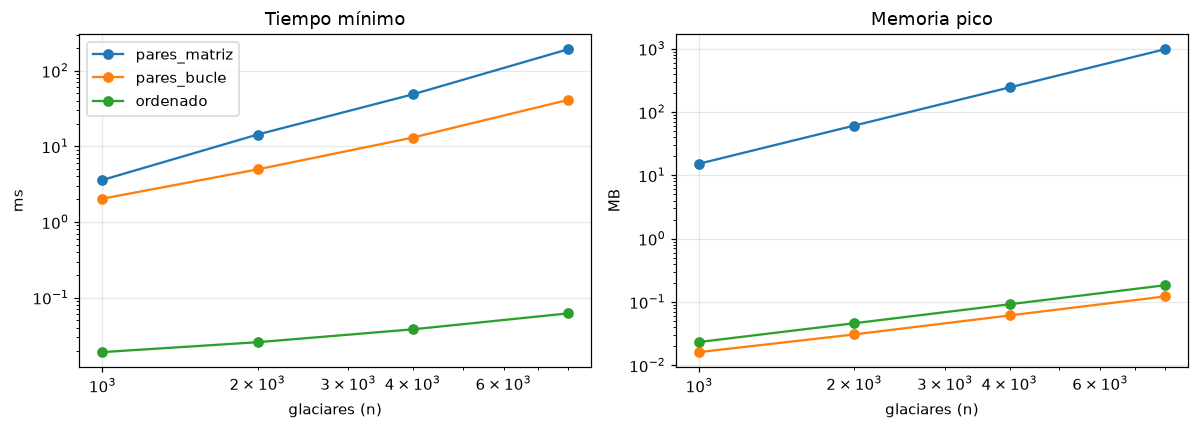

Con n = 8,000: la versión ordenada es 3,096 veces más rápida que la matriz y usa 5,320 veces menos memoria.
Inventario completo (26.180): 0.132 ms y 0.60 MB con la versión ordenada; la escala n·log n desde n = 8,000 predice 0.229 ms.


In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, grupo in t_gini.groupby("implementacion", sort=False):
    ejes[0].loglog(grupo["n"], grupo["ms"], "o-", label=nombre)
    ejes[1].loglog(grupo["n"], grupo["memoria_mb"], "o-", label=nombre)
ejes[0].set(title="Tiempo mínimo", xlabel="glaciares (n)", ylabel="ms")
ejes[1].set(title="Memoria pico", xlabel="glaciares (n)", ylabel="MB")
ejes[0].legend()
plt.tight_layout()
plt.show()

n_max = t_gini["n"].max()
en_n = t_gini[t_gini["n"] == n_max].set_index("implementacion")
print(f"Con n = {n_max:,}: la versión ordenada es {en_n.loc['pares_matriz', 'ms'] / en_n.loc['ordenado', 'ms']:,.0f} veces más rápida "
      f"que la matriz y usa {en_n.loc['pares_matriz', 'memoria_mb'] / en_n.loc['ordenado', 'memoria_mb']:,.0f} veces menos memoria.")
# Inventario completo: 50 repeticiones y el mínimo, contrastado con lo que predice n·log n desde la muestra mayor
gini_completo = me.medir(me.gini_ordenado, limpio["AREA_KM2"].to_numpy(), repeticiones=50)
t_n_max = en_n.loc["ordenado", "ms"]
predicho = t_n_max * (26_180 * np.log(26_180)) / (n_max * np.log(n_max))
print(f"Inventario completo (26.180): {1000 * gini_completo['segundos']:.3f} ms y {gini_completo['memoria_mb']:.2f} MB "
      f"con la versión ordenada; la escala n·log n desde n = {n_max:,} predice {predicho:.3f} ms.")

**Interpretación.**

- **Tiempo frente a memoria.** La versión matriz y la versión bucle tienen el mismo orden de tiempo, O(n²), pero no de memoria. La memoria de la matriz crece con n²: se multiplica por ~4 cada vez que n se duplica, hasta volverse inviable. El bucle mantiene la memoria lineal y, en la práctica, resultó igual de rápido con 1.000 glaciares y más rápido desde 2.000. Cada iteración es una operación vectorizada sobre una fila, mientras que la matriz paga el costo de reservar y recorrer n² celdas. Vectorizar todo no siempre es lo más eficiente.
- **Exponentes observados.** El de la matriz se acerca o supera 2: al crecer, la matriz deja de caber en la caché del procesador. Los del bucle y de la versión ordenada quedan por debajo de su valor teórico porque, en estos tamaños, pesan los costos fijos de cada llamada a NumPy. Esto confirma la advertencia del apunte: en entradas pequeñas los costos fijos ocultan la complejidad, y por eso se mide sobre varios tamaños.
- **Medición sobre el inventario completo: un hallazgo de la revisión.** Una versión anterior informó 2,99 ms con los 26.180 glaciares, unas 15 veces más de lo que predice la escala n·log n desde 8.000 (≈ 0,2 ms). No era ruido: medido por partes dentro de este kernel, el ordenamiento tardaba 0,15 ms y el producto `np.dot(rangos, x)`, 2,7 ms. `np.dot` delega en OpenBLAS, que sobre vectores de este tamaño reparte el cálculo en hilos, y dentro de un kernel de Jupyter despertarlos cuesta milisegundos; con 8.000 elementos no usa hilos y por eso esa medición sí calzaba. `IndiceGini` ahora calcula Σ(i·xᵢ) con `(rangos * x).sum()`, sin BLAS: la medición del inventario completo vuelve a ser coherente con O(n log n). Lección: una cifra que no calza con la complejidad teórica es una pista que hay que investigar, no un dato que reportar.
- **Decisión.** `concentracion.IndiceGini` usa la versión ordenada: es la única que escala al inventario completo, con milisegundos y una memoria lineal.

### 7.3 Participación del 1 % mayor

F2 usaba `nlargest` de pandas. Comparamos tres formas sobre el tamaño real y sobre 4 y 16 veces ese tamaño:

| Implementación | Idea | Tiempo |
|---|---|---|
| `participacion_nlargest` | pandas `nlargest` (F2) | O(n log k) más el costo de crear una Serie |
| `participacion_orden_total` | Ordena todo y suma la cola | O(n log n) |
| `participacion_particion` | `np.partition`: selección parcial (la de `ParticipacionMayores`) | O(n) |

In [24]:
t_participacion = me.comparar({"nlargest_F2": me.participacion_nlargest, "orden_total": me.participacion_orden_total,
                               "particion": me.participacion_particion},
                              me.muestras(limpio["AREA_KM2"], [26180, 104720, 418880]))
display(t_participacion.round(3))
display(me.exponente_empirico(t_participacion))

,n,implementacion,ms,memoria_mb,veces_la_mas_rapida
0,26180,nlargest_F2,0.485,0.604,8.222
1,26180,orden_total,0.100,0.202,1.701
2,26180,particion,0.059,0.203,1.000
3,104720,nlargest_F2,1.311,2.402,7.833
4,104720,orden_total,0.396,0.802,2.366
5,104720,particion,0.167,0.802,1.000
6,418880,nlargest_F2,3.133,9.592,4.787
7,418880,orden_total,1.674,3.198,2.558
8,418880,particion,0.654,3.199,1.000


,implementacion,exponente_tiempo
0,nlargest_F2,0.67
1,orden_total,1.02
2,particion,0.87


La selección parcial es la más rápida en los tres tamaños porque no necesita ordenar todo el arreglo, solo separar los *k* mayores; además evita el costo fijo de construir una Serie de pandas. Las tres dan el mismo porcentaje (`comparar` lo verificó antes de medir). Por eso `ParticipacionMayores` usa `np.partition`.

### 7.4 La medición que cambió el código: normalización del texto

En F2, `normalizar_texto` reparaba y normalizaba **cada uno** de los 26.180 valores de cada columna de texto, aunque se repitieran. Columnas como `REGION` tienen solo 16 valores distintos. La alternativa normaliza los *u* valores únicos una vez y los asigna con un diccionario: O(u) normalizaciones más O(n) búsquedas, en lugar de O(n) normalizaciones.

In [25]:
filas = []
for columna in ("REGION", "FUENTE_DIG", "NOMBRE"):
    t = me.comparar({"fila_a_fila_F2": me.normalizar_fila_a_fila, "valores_unicos_F3": me.normalizar_por_valores_unicos},
                    {len(original): original[columna]})
    t.insert(0, "columna", columna)
    t.insert(1, "valores_distintos", original[columna].nunique())
    filas.append(t)
t_texto = pd.concat(filas, ignore_index=True)
display(t_texto.round(3))

,columna,valores_distintos,n,implementacion,ms,memoria_mb,veces_la_mas_rapida
0,REGION,16,26180,fila_a_fila_F2,16.694,3.149,2.911
1,REGION,16,26180,valores_unicos_F3,5.736,1.710,1.000
2,FUENTE_DIG,19,26180,fila_a_fila_F2,11.032,2.518,2.002
3,FUENTE_DIG,19,26180,valores_unicos_F3,5.510,1.710,1.000
4,NOMBRE,431,26180,fila_a_fila_F2,8.931,2.357,1.660
5,NOMBRE,431,26180,valores_unicos_F3,5.381,1.716,1.000


**Interpretación y decisión.** La mejora es mayor cuantos menos valores distintos tiene la columna (`REGION`, 16 valores) y menor en `NOMBRE`, donde hay más nombres distintos. En todos los casos el resultado es idéntico y la memoria pico baja a cerca de la mitad, porque no se crea una cadena nueva por fila. **Esta medición cambió el código:** la versión por valores únicos se adoptó en `limpieza.normalizar_texto` (commit `perf:` del repositorio), y la sección 4 confirma que las salidas siguen idénticas a las de F2.

| Cálculo | Implementación elegida | Tiempo | Memoria | Motivo |
|---|---|---|---|---|
| Gini | Ordenado | O(n log n) | O(n) | La definición por pares es inviable en memoria (matriz) o en tiempo (bucle) |
| Participación de los mayores | `np.partition` | O(n) | O(n) | No ordena todo; sin el costo fijo de pandas |
| Normalización del texto | Valores únicos + diccionario | O(u + n) | O(u) | Menos trabajo repetido; mismo resultado |

## 8. Recursividad

Los metadatos de cada fase son un diccionario anidado: proyecto → datos → fuente, decisiones → imputación → HMIN → método… Para guardarlos como una tabla de dos columnas (clave, valor) hay que recorrerlos completos **sin saber de antemano cuántos niveles tienen**. Ese es el caso en que la recursión se justifica: cada subdiccionario se trata igual que el diccionario completo.

`md.aplanar` (trasladada de F2, sección 7) tiene dos partes:
- **caso base:** el valor no es un diccionario → se guarda con su ruta `a.b.c`;
- **caso recursivo:** el valor es un diccionario → se aplana con la ruta acumulada como prefijo.

In [26]:
imputador = pipelines["limpieza"]["ImputadorEstrategia(HMIN)"]
METADATOS_F3 = {
    "proyecto": {"fase": "F3", "semilla": utl.SEMILLA, "commit_codigo": utl.commit_contenido(RAIZ)},
    "datos": {"archivo": utl.ARCHIVO_INVENTARIO, "sha256": huella_inicial,
              "dimensiones": {"filas": original.shape[0], "columnas": original.shape[1]}},
    "nucleo": {"pipelines": {n: [p.nombre for p in pl.pasos] for n, pl in pipelines.items()},
               "imputacion": {"HMIN": {"metodo": imputador.parametros["metodo"],
                                       "candidatas": [e.etiqueta for e in imp.estrategias_hmin()]}},
               "verificacion_F2": {r.archivo: bool(r.identico) for r in verificacion.itertuples()}},
    "resultados": {"superficie": {k: round(v, 3) for k, v in resumen_superficie.items() if k != "magnitud"},
                   "volumen": {k: round(float(v), 3) for k, v in fila.loc["VOL_km3"].items()}},
}
metadatos_planos = md.aplanar(METADATOS_F3)
print(f"Profundidad: {md.profundidad(METADATOS_F3)} niveles → {len(metadatos_planos)} pares clave-valor")
display(pd.DataFrame(list(metadatos_planos.items()), columns=["clave", "valor"]))

Profundidad: 4 niveles → 25 pares clave-valor


,clave,valor
0,proyecto.fase,F3
1,proyecto.semilla,42
2,proyecto.commit_codigo,c5d9daa
3,datos.archivo,Inventario_Publico_de_Glaciares_2022.csv
4,datos.sha256,5691de5d7d7ffe2c8586a7066e227ac5cc91fa1ec69f54096e937a054c283f1d
5,datos.dimensiones.filas,26180
6,datos.dimensiones.columnas,45
7,nucleo.pipelines.limpieza,"DescartadorColumnas, NormalizadorTexto, ConversorTipos, ReconstructorVolumen..."
8,nucleo.pipelines.formato,"Redondeador, Categorizador"
9,nucleo.pipelines.modelo,"CodificadorOrdinal(MZON_GLAC), CodificadorOrdinal(CLASE_TAMANO), Codificador..."


### 8.1 Recursión frente a una pila explícita

`md.aplanar_iterativo` produce el mismo diccionario, en el mismo orden, reemplazando las llamadas recursivas por una pila. Comparamos ambas sobre estructuras de 10, 100 y 500 niveles con 5 valores por nivel:

In [27]:
t_aplanar = me.comparar({"recursiva": me.aplanar_recursivo, "pila": me.aplanar_con_pila},
                        {n: md.anidar(n, hojas=5) for n in (10, 100, 500)})
display(t_aplanar.round(4))
print("Límite de recursión de Python:", sys.getrecursionlimit())
profunda = md.anidar(5000)
try:
    md.aplanar(profunda)
except RecursionError:
    print("aplanar recursiva con 5.000 niveles → RecursionError")
print(f"aplanar_iterativo con 5.000 niveles → {len(md.aplanar_iterativo(profunda)):,} claves")

,n,implementacion,ms,memoria_mb,veces_la_mas_rapida
0,10,recursiva,0.0142,0.0056,1.0000
1,10,pila,0.0162,0.0048,1.1372
2,100,recursiva,0.2130,0.1368,1.1923
3,100,pila,0.1787,0.1233,1.0000
4,500,recursiva,2.9123,2.9470,2.0510
5,500,pila,1.4199,2.8927,1.0000


Límite de recursión de Python: 1000
aplanar recursiva con 5.000 niveles → RecursionError
aplanar_iterativo con 5.000 niveles → 5,000 claves


**Interpretación y decisión.** Ambas recorren cada valor una vez: tiempo O(número de valores) y memoria O(profundidad) para la pila de llamadas o la pila explícita. La versión con pila es algo más rápida, porque una llamada a función en Python cuesta más que agregar a una lista, y **no tiene límite de profundidad**; la recursiva falla al superar el límite de Python (alrededor de 1.000 llamadas).

Para este proyecto **se mantiene la versión recursiva**: los metadatos tienen 4 niveles, muy lejos del límite, y el código recursivo expresa la estructura del problema de forma más directa y legible. La versión iterativa queda documentada y probada para estructuras de profundidad arbitraria. Es una decisión argumentada, no una recursión forzada.

In [28]:
import pruebas_medicion
resultado_medicion = utl.ejecutar_pruebas(pruebas_medicion.pruebas())
display(resultado_medicion)
assert resultado_medicion["resultado"].eq("OK").all(), "Hay pruebas de medición fallidas"
print(f"{len(resultado_medicion)}/{len(resultado_medicion)} OK:", resultado_medicion["tipo"].value_counts().to_dict())

,tipo,prueba,resultado
0,normal,"medir devuelve tiempo, memoria y el resultado de la función",OK
1,normal,Las tres implementaciones del Gini dan el mismo valor,OK
2,normal,Las tres formas de calcular la participación dan el mismo valor,OK
3,normal,Normalizar por valores únicos = normalizar fila a fila (F2),OK
4,normal,aplanar recursivo e iterativo dan el mismo diccionario y orden de claves,OK
5,normal,comparar devuelve una fila por tamaño e implementación,OK
6,normal,exponente_empirico recupera b = 1 en un costo lineal y b = 2 en uno cuadrático,OK
7,normal,profundidad de los metadatos de ejemplo = 4,OK
8,límite,aplanar un diccionario vacío devuelve {} en ambas versiones,OK
9,límite,La versión iterativa aplana 5.000 niveles; la recursiva supera el límite de ...,OK


16/16 OK: {'normal': 8, 'límite': 4, 'excepción': 4}


## 9. Patrones de diseño

Usamos dos patrones, porque el proyecto tenía los dos problemas que resuelven (Gamma et al., 1994). No aplicamos Factory ni Singleton: no había un problema que justificara su complejidad.

### 9.1 Strategy: la imputación de HMIN

**Problema en F2.** Las cuatro formas de imputar `HMIN` eran ramas de un `if` dentro de `imputar()`; agregar una quinta obligaba a modificar esa función y la que las comparaba.

**Solución.** Cada forma es una clase con la misma interfaz (`ajustar`, `estimar`), y `ImputadorEstrategia` recibe la lista de estrategias como parámetro. Al ajustar, las compara con la regla declarada en F2 (sin pérdida de filas, sin violar `HMIN ≤ HMEDIA` y menor cambio de la desviación estándar) y elige una:

In [29]:
display(imputador.parametros["comparacion"])
print("Estrategia elegida:", imputador.parametros["metodo"])

,metodo,filas,desv_est,violaciones,area_perdida_km2,cambio_desv_pct
0,eliminar filas,26146,1260.28,0,967.51,-0.0000
1,media global,26179,1259.48,33,0.00,-0.0630
2,mediana global,26179,1259.56,31,0.00,-0.0568
3,mediana por comuna,26179,1260.08,14,0.00,-0.0155
4,HMEDIA − desnivel mediano por comuna,26179,1260.24,0,0.00,-0.0029


Estrategia elegida: HMEDIA − desnivel mediano por comuna


**Consecuencia.** Cambiar la estrategia no modifica ninguna clase: basta con pasar otra al construir el pipeline. Por ejemplo, forzar la mediana global, que la regla descartó:

In [30]:
alternativo = proc.pipeline_limpieza(estrategias_hmin=[imp.PorMediana()]).ajustar_transformar(original)
imputados = alternativo["HMIN_IMPUTADO"] == 1
print(f"Con la mediana global: {imputados.sum()} valores imputados; "
      f"{(alternativo.loc[imputados, 'HMIN'] > alternativo.loc[imputados, 'HMEDIA']).sum()} violan HMIN ≤ HMEDIA")
print(f"Con la estrategia elegida: {(limpio.loc[limpio['HMIN_IMPUTADO'] == 1, 'HMIN'] > limpio.loc[limpio['HMIN_IMPUTADO'] == 1, 'HMEDIA']).sum()} violaciones")

Con la mediana global: 33 valores imputados; 31 violan HMIN ≤ HMEDIA
Con la estrategia elegida: 0 violaciones


Sin el patrón, esta comparación habría exigido editar la función de imputación. Con él, la clase que imputa quedó intacta.

### 9.2 Observer: la bitácora se genera al ejecutar

**Problema en F2.** Cada decisión se registraba a mano en la bitácora después de calcularla; si el código cambiaba, la cifra anotada podía quedar desactualizada.

**Solución.** El `Pipeline` notifica a cada observador suscrito al terminar un paso (nombre, filas, columnas, segundos, parámetros y evidencia) sin saber quién escucha. `ObservadorBitacora` escribe esa evidencia en la `Bitacora` del proyecto; `RegistroEjecucion` y `ReporteConsola` (sección 3.1) son otros observadores del mismo aviso.

**Consecuencia.** La bitácora de F3 no se redacta: se produce en cada ejecución y no puede quedar desactualizada.

In [31]:
bitacora_f3 = utl.Bitacora("F3")
with contextlib.redirect_stdout(io.StringIO()):          # la bitácora imprime cada registro; se muestra como tabla
    proc.procesar(original, observadores=[ObservadorBitacora(bitacora_f3, proc.DECISIONES)])
display(bitacora_f3.tabla())
RUTA_BITACORA = RAIZ / "docs" / "bitacora_f3.md"
bitacora_f3.exportar_markdown(RUTA_BITACORA)
print(f"{len(bitacora_f3)} decisiones → {RUTA_BITACORA.relative_to(RAIZ)}")

,n,etapa,decision,evidencia
0,1,limpieza,Se descartan columnas sin información y redundantes; CH_CASQ pasa a EN_CAMPO...,descartadas = 9; EN_CAMPO_HIELO = 723
1,2,limpieza,"Se normaliza el texto (codificación, mayúsculas y espacios)","valores_corregidos = 139; por_columna = {'NOMBRE': 5, 'FUENTE_DIG': 6, 'NOM_..."
2,3,limpieza,"Casting: coordenadas a float, FUEN_FECHA a fecha + FUEN_ANIO, códigos a texto",coordenadas_nulas = 0; fechas_completas = 26168; anios = 26180
3,4,limpieza,Se recalculan los ceros de VOL_km3 y EQ_AGUAKM3 con la fórmula del inventario,volumenes = 362; equivalentes = 668
4,5,limpieza,Los faltantes encubiertos de HMIN y HMEDIA se marcan como NaN,HMIN = 33; HMEDIA = 1
5,6,limpieza,HMIN se imputa con la estrategia elegida por la regla declarada,metodo = HMEDIA − desnivel mediano por comuna; imputados = 33
6,7,limpieza,HMEDIA incoherente se reemplaza por (HMIN + HMAX) / 2,imputados = 1
7,8,limpieza,"Se derivan RANGO_ALT, LOG_AREA, LOG_VOL, CLASE_TAMANO, FRENTE_AGUA y FUENTE_...",asimetria_log_area = 0.61; asimetria_log_vol = 0.69
8,9,modelo,"One-hot para CLASIFICA, FRENTE_TER, REGION y FUENTE_GRUPO",columnas_binarias = 32


9 decisiones → docs/bitacora_f3.md


## 10. Resultados para la Fase 4

La Fase 4 comunicará estos resultados con tablas y visualizaciones. Dejamos en `data/processed/` las tablas de concentración, con la superficie y el volumen lado a lado para cada grupo, y en `docs/` los metadatos aplanados. Al releerlas se comprueba su forma.

In [32]:
volumen = con.AnalisisConcentracion(limpio, "VOL_km3", con.medidas_proyecto())

def lado_a_lado(grupo):
    # % de superficie y de volumen que aporta cada grupo, y su Gini interno
    s = superficie.por_grupo(grupo)[["glaciares", "pct", "gini"]].add_suffix("_superficie")
    v = volumen.por_grupo(grupo)[["pct", "gini"]].add_suffix("_volumen")
    return s.join(v).rename(columns={"glaciares_superficie": "glaciares"}).reset_index()

SALIDAS = {
    "concentracion_magnitudes_f3.csv": magnitudes,
    "concentracion_region_f3.csv": lado_a_lado("REGION"),
    "concentracion_clasificacion_f3.csv": lado_a_lado("CLASIFICA"),
    "concentracion_macrozona_f3.csv": lado_a_lado("MZON_GLAC"),
    "lorenz_f3.csv": curva_superficie.rename(columns={"prop_magnitud": "prop_superficie"})
                     .assign(prop_volumen=curva_volumen["prop_magnitud"].to_numpy()),
}
for nombre, tabla in SALIDAS.items():
    ruta = RAIZ / "data" / "processed" / nombre
    tabla.to_csv(ruta, index=False, lineterminator="\n")
    relectura = pd.read_csv(ruta)
    assert relectura.shape == tabla.shape and list(relectura.columns) == list(tabla.columns), nombre
    print(f"{ruta.relative_to(RAIZ)}: {tabla.shape[0]} × {tabla.shape[1]} (relectura verificada)")

RUTA_METADATOS = RAIZ / "docs" / "metadatos_f3.csv"
pd.DataFrame(list(metadatos_planos.items()), columns=["clave", "valor"]).to_csv(RUTA_METADATOS, index=False, lineterminator="\n")
print(f"{RUTA_METADATOS.relative_to(RAIZ)}: {len(metadatos_planos)} claves")
assert utl.huella_sha256(RUTA_ORIGINAL) == huella_inicial, "data/raw fue modificado"
print("data/raw intacto (SHA-256 igual al inicial).")

data/processed/concentracion_magnitudes_f3.csv: 3 × 6 (relectura verificada)
data/processed/concentracion_region_f3.csv: 16 × 6 (relectura verificada)
data/processed/concentracion_clasificacion_f3.csv: 5 × 6 (relectura verificada)
data/processed/concentracion_macrozona_f3.csv: 4 × 6 (relectura verificada)
data/processed/lorenz_f3.csv: 201 × 3 (relectura verificada)
docs/metadatos_f3.csv: 25 claves
data/raw intacto (SHA-256 igual al inicial).


In [33]:
display(SALIDAS["concentracion_clasificacion_f3.csv"].round(3))

,CLASIFICA,glaciares,pct_superficie,gini_superficie,pct_volumen,gini_volumen
0,GLACIAR EFLUENTE,217,65.379,0.709,90.054,0.830
1,GLACIAR DE MONTAÑA,3844,19.646,0.499,5.128,0.663
2,GLACIAR DE VALLE,310,8.902,0.535,4.311,0.677
3,GLACIARETE,18211,3.770,0.602,0.321,0.710
4,GLACIAR ROCOSO,3598,2.304,0.594,0.186,0.743


## 11. Conclusiones y reflexión técnica

### Qué cambió desde la Fase 2
- **De celdas a componentes.** Los pasos del pipeline son 15 clases con un contrato común (`Transformador`), encadenadas por un `Pipeline` que no conoce su tipo. Las funciones sin estado siguen siendo funciones (`limpieza.py`): una clase se justifica solo cuando debe recordar algo entre `ajustar` y `transformar`.
- **Misma salida, comprobada.** Los tres archivos de `data/processed` son idénticos byte a byte a los de F2 (sección 4), y 69 pruebas (29 + 24 + 16) cubren casos normales, límite y excepciones.
- **Optimización medida.** La comparación de implementaciones justificó el Gini ordenado y la selección parcial, y cambió la normalización del texto en el código del proyecto (sección 7.4).

### Hallazgos
- La **superficie** glaciar de Chile está extremadamente concentrada: el 1 % de los glaciares reúne el 71,5 % y el 10 % el 91,1 % (Gini 0,937); Magallanes y Aysén, el 91,1 %.
- La concentración **cambia según la clasificación**: 217 glaciares efluentes reúnen el 65,4 % de la superficie, mientras 18.211 glaciaretes aportan el 3,8 %. Dentro de cada tipo el Gini es moderado (0,50–0,71).
- La concentración del **volumen** (93,8 %, Gini 0,991) **no es un hallazgo independiente**: un volumen calculado solo desde la superficie la reproduce exactamente.

### Limitaciones y decisiones abiertas para la Fase 4
- El inventario es transversal: no permite hablar de pérdida de hielo en el tiempo.
- Las medidas tratan cada glaciar como una unidad; un glaciar efluente puede formar parte de un campo de hielo mayor (bandera `EN_CAMPO_HIELO`), lo que conviene declarar al comunicar.
- La separación `ajustar`/`transformar` deja el pipeline listo para un esquema entrenamiento/prueba si la Fase 4 incorporara un modelo.

## Referencias

Chen, J., & Ohmura, A. (1990). Estimation of Alpine glacier water resources and their change since the 1870s. En H. Lang & A. Musy (Eds.), *Hydrology in mountainous regions I* (IAHS Publication N.º 193, pp. 127–135). International Association of Hydrological Sciences.

Dirección General de Aguas. (2022). *Inventario público de glaciares de Chile 2022* [Conjunto de datos]. Ministerio de Obras Públicas. https://dga.mop.gob.cl/inventario-publico-glaciares/

Gamma, E., Helm, R., Johnson, R., & Vlissides, J. (1994). *Design patterns: Elements of reusable object-oriented software*. Addison-Wesley.

McKinney, W. (2022). *Python for data analysis* (3.ª ed.). O'Reilly Media.

Python Software Foundation. (s. f.-a). *timeit — Measure execution time of small code snippets*. https://docs.python.org/3/library/timeit.html

Python Software Foundation. (s. f.-b). *tracemalloc — Trace memory allocations*. https://docs.python.org/3/library/tracemalloc.html

Rule, A., Birmingham, A., Zuniga, C., Altintas, I., Huang, S.-C., Knight, R., Moshiri, N., Nguyen, M. H., Rosenthal, S. B., Pérez, F., & Rose, P. W. (2019). Ten simple rules for writing and sharing computational analyses in Jupyter Notebooks. *PLOS Computational Biology, 15*(7), e1007007. https://doi.org/10.1371/journal.pcbi.1007007

Salinas, O. (2026). Programación para la ciencia de datos: Semana 2 [Diapositivas de clase, MCDI500]. Universidad Andrés Bello.

scikit-learn developers. (2026). Preprocessing data (Versión 1.9) [Documentación de software]. https://scikit-learn.org/stable/modules/preprocessing.html


The pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/

